In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\PCA\customerdatapca.csv')

In [3]:
df.head()

,Customer_ID,Age,Annual_Income,Annual_Spending,Website_Visits_Per_Month,Monthly_Orders,Discount_Sensitivity_Score,Email_Click_Rate,App_Usage_Hours_Per_Month,Loyalty_Points,Return_Rate,Customer_Satisfaction,Cart_Abandonment_Rate,True_Customer_Group
0,CUST00001,18,43453,10662,5,0,2,0.146,2.60,575,0.158,2.0,0.587,1
1,CUST00002,52,61020,44539,22,3,7,0.406,6.50,1843,0.066,3.2,0.420,3
2,CUST00003,58,67522,41499,18,2,8,0.328,5.20,1843,0.068,2.8,0.470,3
3,CUST00004,20,43614,12949,5,1,2,0.138,4.02,643,0.165,2.2,0.579,1
4,CUST00005,33,101732,21781,34,7,4,0.530,9.19,1087,0.136,4.0,0.338,2


In [4]:
df.isnull().sum()

Customer_ID                   0
Age                           0
Annual_Income                 0
Annual_Spending               0
Website_Visits_Per_Month      0
Monthly_Orders                0
Discount_Sensitivity_Score    0
Email_Click_Rate              0
App_Usage_Hours_Per_Month     0
Loyalty_Points                0
Return_Rate                   0
Customer_Satisfaction         0
Cart_Abandonment_Rate         0
True_Customer_Group           0
dtype: int64

In [7]:
X = df.drop(columns=['Customer_ID', 'True_Customer_Group'])

print(X.shape)

(7000, 12)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

print("Scaled data shape:", x_scaled.shape)

Scaled data shape: (7000, 12)


In [22]:
# create a PCA model 

# Retain enough component to explain at least 95% of the varieance 

from sklearn.decomposition import PCA

pca = PCA(n_components=5)

# apply PCA to the standarize data 

X_pca = pca.fit_transform(x_scaled)

# Display the original and reduced dimension

print("Original number of features:", x_scaled.shape[1])
print("Number of principle component", X_pca.shape[1])

# Display the total variance retained

print("Varience retained ", round(pca.explained_variance_ratio_.sum()*100))

Original number of features: 12
Number of principle component 5
Varience retained  97


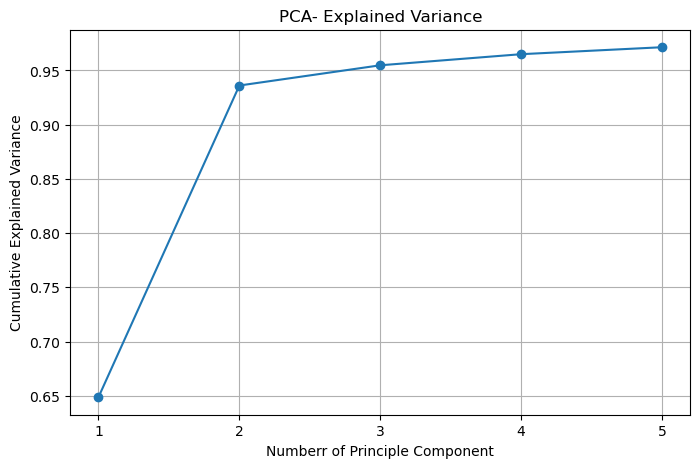

In [23]:
# calcualte cummulative explained variance
import matplotlib.pyplot as plt 
cumulative_variance = pca.explained_variance_ratio_.cumsum()

# plot cummulative explined variance 
plt.figure(figsize=(8,5))

plt.plot(
    range (1, len(cumulative_variance)+1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Numberr of Principle Component")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA- Explained Variance")
plt.xticks(range(1, len(cumulative_variance)+1))
plt.grid(True)
plt.show()

In [28]:
# create the DBSCAAN
# eps control the neighbour distance
# in_sample control the minimum neighbour
from sklearn.cluster import DBSCAN

dbscan =DBSCAN(eps=1.5, min_samples=10)

cluster= dbscan.fit_predict(X_pca)

# store the cluster labels in new Datafarame

pca_df = pd.DataFrame(
    X_pca, 
    columns=[f'PC{i+1}' for i in  range(X_pca.shape[1])]
)

pca_df['Cluster']= cluster

# Display the first five rows 
print(pca_df.head())


        PC1       PC2       PC3       PC4       PC5  Cluster
0 -4.870306 -0.119700 -0.203558 -0.031265  0.385555        0
1  1.706263  2.174699  0.002019 -0.586820 -0.491050        1
2  0.936699  2.945449  0.001586  0.022502  0.233738        1
3 -4.397044 -0.359247  0.332591 -0.006214  0.219159        0
4  2.499756 -2.652934 -0.325511 -0.135245 -0.005456        2


In [30]:
# count customer in each cluster
print('Customer in each cluster')
print(pca_df['Cluster'].value_counts().sort_index())

# count cluster, exclusing noise points labelled -1

number_of_cluster = len(set(cluster)-{-1})

# count noise point 

number_of_noise_point = sum(cluster == -1)

print('\nNumber of cluster:', number_of_cluster)
print("Number of noise points: ", number_of_noise_point)

Customer in each cluster
Cluster
0    2334
1    2333
2    2333
Name: count, dtype: int64

Number of cluster: 3
Number of noise points:  0


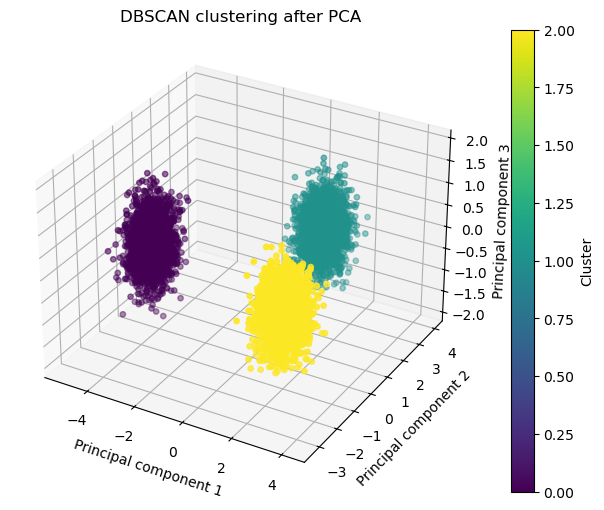

In [45]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    pca_df["PC3"],
    # pca_df['PC4'],
    # pca_df['PC5'],
    c=pca_df["Cluster"],
    cmap="viridis",
    s=15
)

ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_zlabel("Principal component 3")
ax.set_title("DBSCAN clustering after PCA")

fig.colorbar(scatter, ax=ax, label="Cluster")
plt.show()

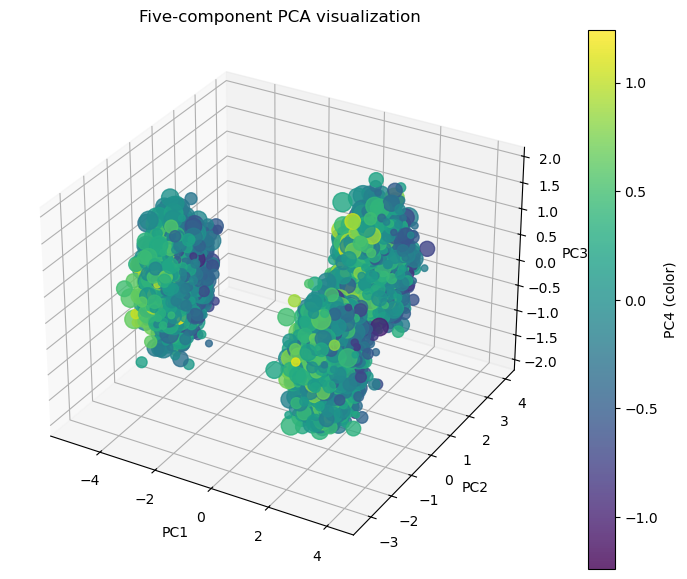

In [43]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    pca_df["PC3"],
    c=pca_df["PC4"],                    # 4th dimension: color
    s=20 + 180 * pca_df["PC5"].rank(pct=True),  # 5th dimension: size
    cmap="viridis",
    alpha=0.8
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Five-component PCA visualization")

fig.colorbar(scatter, ax=ax, label="PC4 (color)")
plt.show()

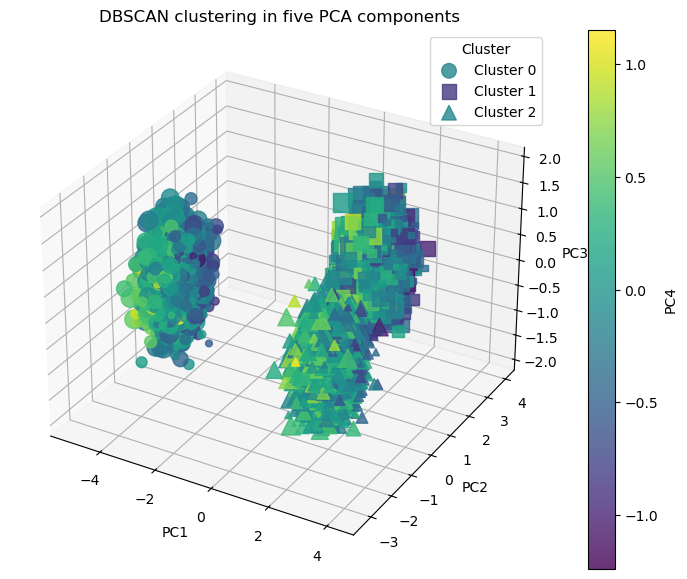

In [44]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# Map PC5 to point size
sizes = 20 + 180 * pca_df["PC5"].rank(pct=True)
markers = ["o", "s", "^", "D", "v", "P", "X", "*"]

for i, cluster in enumerate(sorted(pca_df["Cluster"].unique())):
    group = pca_df[pca_df["Cluster"] == cluster]

    scatter = ax.scatter(
        group["PC1"],
        group["PC2"],
        group["PC3"],
        c=group["PC4"],              # 4th component: color
        s=sizes.loc[group.index],    # 5th component: size
        cmap="viridis",
        marker=markers[i % len(markers)],
        label=f"Cluster {cluster}",
        alpha=0.8
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("DBSCAN clustering in five PCA components")

fig.colorbar(scatter, ax=ax, label="PC4")
ax.legend(title="Cluster")
plt.show()

In [46]:
from sklearn.metrics import silhouette_score

labels = pca_df["Cluster"].to_numpy()
non_noise = labels != -1

if len(set(labels[non_noise])) >= 2:
    score = silhouette_score(X_pca[non_noise], labels[non_noise])
    print(f"Silhouette score: {score:.3f}")
else:
    print("Silhouette score requires at least two non-noise clusters.")

Silhouette score: 0.767
